<a href="https://colab.research.google.com/github/bandapraneeth/Quantum-Hackathon/blob/main/question_32.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install pennylane scikit-learn pandas numpy matplotlib seaborn torch

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 69.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 937.5/937.5 kB 22.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 25.5/25.5 MB 97.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 71.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.9/7.9 MB 99.3 MB/s  0:00:00
  Attempting uninstall: autograd
    Found existing installation: autograd 1.9.1
    Uninstalling autograd-1.9.1:
      Successfully uninstalled autograd-1.9.1
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8/8 [pennylane]


In [26]:
import pandas as pd
from google.colab import files

sine_df = pd.DataFrame({
    "Time": np.arange(len(sine_data)),
    "Value": sine_data
})

sine_df.to_csv("Noisy_Sine_D19.csv", index=False)

files.download("Noisy_Sine_D19.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [27]:
narma_df = pd.DataFrame({
    "Time": np.arange(len(narma_input)),
    "Input": narma_input,
    "Output": narma_output
})

narma_df.to_csv("NARMA10_D20.csv", index=False)

files.download("NARMA10_D20.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [2]:
import pennylane as qml
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn

import time
import random

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

random.seed(42)
np.random.seed(42)
torch.manual_seed(42)

print("All libraries imported successfully!")
print("PennyLane version:", qml.__version__)
print("PyTorch version:", torch.__version__)

All libraries imported successfully!
PennyLane version: 0.45.1
PyTorch version: 2.14.1+cpu


In [3]:
n = 1200

t = np.linspace(0, 40, n)

sine_data = (
    np.sin(t) +
    0.3 * np.sin(3 * t) +
    np.random.normal(0, 0.15, n)
)

print("Noisy Sine Dataset")
print("Total observations:", len(sine_data))
print("Minimum:", sine_data.min())
print("Maximum:", sine_data.max())

Noisy Sine Dataset
Total observations: 1200
Minimum: -1.3467086053257247
Maximum: 1.4775942900322168


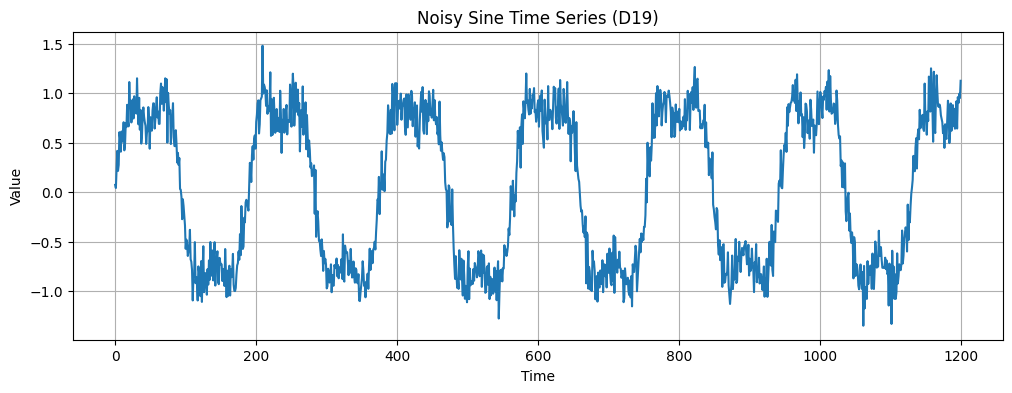

In [4]:
plt.figure(figsize=(12, 4))

plt.plot(sine_data)

plt.title("Noisy Sine Time Series (D19)")
plt.xlabel("Time")
plt.ylabel("Value")

plt.grid()
plt.show()

In [5]:
def generate_narma10(n=1200):

    u = np.random.uniform(0, 0.5, n)
    y = np.zeros(n)

    for t in range(10, n - 1):

        y[t + 1] = (
            0.3 * y[t]
            + 0.05 * y[t] * np.sum(y[t-9:t+1])
            + 1.5 * u[t-9] * u[t]
            + 0.1
        )

    return u, y


narma_input, narma_output = generate_narma10()

print("NARMA-10 Dataset")
print("Input observations:", len(narma_input))
print("Output observations:", len(narma_output))

NARMA-10 Dataset
Input observations: 1200
Output observations: 1200


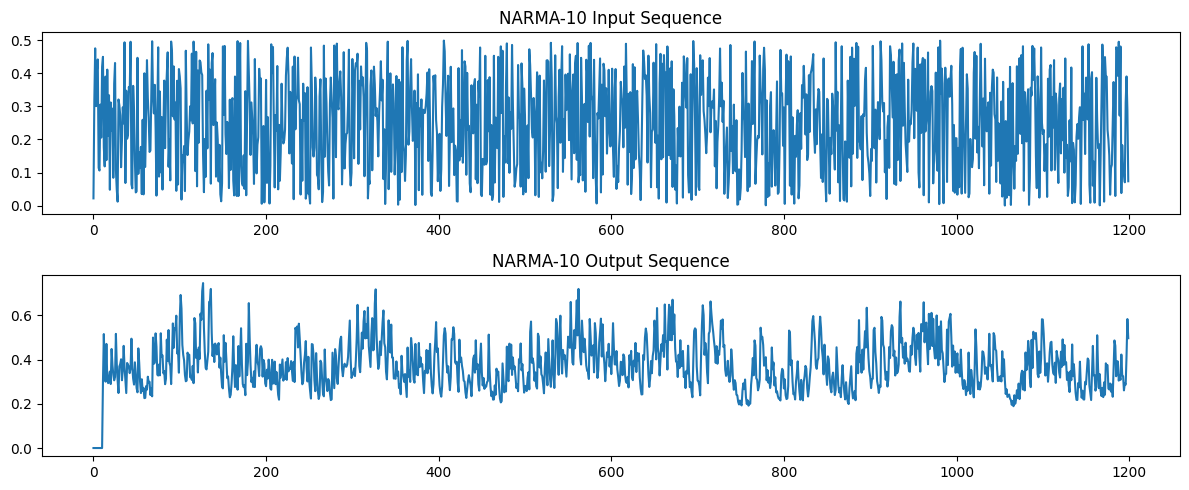

In [6]:
plt.figure(figsize=(12, 5))

plt.subplot(2, 1, 1)
plt.plot(narma_input)
plt.title("NARMA-10 Input Sequence")

plt.subplot(2, 1, 2)
plt.plot(narma_output)
plt.title("NARMA-10 Output Sequence")

plt.tight_layout()
plt.show()

In [7]:
SEQ_LEN = 10

def prepare_sequences(X, y):

    n = len(X)

    train_end = int(n * 0.70)
    val_end = int(n * 0.85)

    splits = {
        "train": (X[:train_end], y[:train_end]),
        "val": (X[train_end:val_end], y[train_end:val_end]),
        "test": (X[val_end:], y[val_end:])
    }

    x_scaler = StandardScaler()
    y_scaler = StandardScaler()

    x_scaler.fit(splits["train"][0])
    y_scaler.fit(splits["train"][1].reshape(-1, 1))

    result = {}

    for name, (xs, ys) in splits.items():

        xs = x_scaler.transform(xs)
        ys = y_scaler.transform(
            ys.reshape(-1, 1)
        ).flatten()

        X_seq = []
        y_seq = []

        for i in range(SEQ_LEN, len(xs)):
            X_seq.append(xs[i-SEQ_LEN:i])
            y_seq.append(ys[i])

        result[name] = (
            torch.tensor(np.array(X_seq), dtype=torch.float32),
            torch.tensor(np.array(y_seq), dtype=torch.float32)
        )

    return result, x_scaler, y_scaler

In [8]:
sine_X = sine_data.reshape(-1, 1)
sine_y = sine_data

narma_X = np.column_stack([
    narma_input,
    narma_output
])

narma_y = narma_output

sine_splits, sine_x_scaler, sine_y_scaler = prepare_sequences(
    sine_X, sine_y
)

narma_splits, narma_x_scaler, narma_y_scaler = prepare_sequences(
    narma_X, narma_y
)

print("Sine Dataset:")
for name, data in sine_splits.items():
    print(name, data[0].shape)

print("\nNARMA Dataset:")
for name, data in narma_splits.items():
    print(name, data[0].shape)

Sine Dataset:
train torch.Size([830, 10, 1])
val torch.Size([170, 10, 1])
test torch.Size([170, 10, 1])

NARMA Dataset:
train torch.Size([830, 10, 2])
val torch.Size([170, 10, 2])
test torch.Size([170, 10, 2])


In [9]:
n_qubits = 4
n_layers = 1

dev = qml.device(
    "default.qubit",
    wires=n_qubits
)

@qml.qnode(dev, interface="torch")
def quantum_circuit(inputs, weights):

    qml.AngleEmbedding(
        inputs,
        wires=range(n_qubits),
        rotation="Y"
    )

    qml.StronglyEntanglingLayers(
        weights,
        wires=range(n_qubits)
    )

    return tuple(
        qml.expval(qml.PauliZ(i))
        for i in range(n_qubits)
    )


weight_shapes = {
    "weights": (n_layers, n_qubits, 3)
}

print("Quantum circuit initialized!")
print("Number of qubits:", n_qubits)
print("Number of layers:", n_layers)

Quantum circuit initialized!
Number of qubits: 4
Number of layers: 1


In [14]:
class QuantumLSTM(nn.Module):

    def __init__(self, input_size, hidden_size=4):

        super().__init__()

        self.hidden_size = hidden_size

        self.encoder = nn.Linear(
            input_size + hidden_size,
            n_qubits
        )

        self.quantum_layer = qml.qnn.TorchLayer(
            quantum_circuit,
            weight_shapes
        )

        self.gates = nn.Linear(
            n_qubits + input_size + hidden_size,
            4 * hidden_size
        )

        self.fc = nn.Linear(hidden_size, 1)

    def forward(self, x):

        batch_size, seq_len, _ = x.shape

        h = torch.zeros(batch_size, self.hidden_size)
        c = torch.zeros(batch_size, self.hidden_size)

        for t in range(seq_len):

            xt = x[:, t, :]

            combined = torch.cat([xt, h], dim=1)

            encoded = torch.tanh(self.encoder(combined))

            q_out = self.quantum_layer(encoded)

            # Fix quantum output dimensions
            q_out = q_out.reshape(batch_size, -1)

            gate_input = torch.cat(
                [q_out, xt, h],
                dim=1
            )

            gates = self.gates(gate_input)

            i, f, g, o = gates.chunk(4, dim=1)

            i = torch.sigmoid(i)
            f = torch.sigmoid(f)
            g = torch.tanh(g)
            o = torch.sigmoid(o)

            c = f * c + i * g

            h = o * torch.tanh(c)

        return self.fc(h)

In [15]:
sine_model = QuantumLSTM(input_size=1)
narma_model = QuantumLSTM(input_size=2)

print("Quantum LSTM models initialized successfully!")

Quantum LSTM models initialized successfully!


In [16]:
print("Training Quantum LSTM on Noisy Sine")

sine_train_losses, sine_val_losses, sine_time = train_model(
    sine_model,
    sine_splits["train"],
    sine_splits["val"]
)

print("\nTraining Quantum LSTM on NARMA-10")

narma_train_losses, narma_val_losses, narma_time = train_model(
    narma_model,
    narma_splits["train"],
    narma_splits["val"]
)

Training Quantum LSTM on Noisy Sine
Epoch 1/20 | Train Loss: 1.18180 | Val Loss: 1.10509
Epoch 2/20 | Train Loss: 1.14999 | Val Loss: 1.08463
Epoch 3/20 | Train Loss: 1.11802 | Val Loss: 1.06435
Epoch 4/20 | Train Loss: 1.08596 | Val Loss: 1.04435
Epoch 5/20 | Train Loss: 1.05395 | Val Loss: 1.02446
Epoch 6/20 | Train Loss: 1.02203 | Val Loss: 1.00413
Epoch 7/20 | Train Loss: 0.99003 | Val Loss: 0.98287
Epoch 8/20 | Train Loss: 0.95769 | Val Loss: 0.96021
Epoch 9/20 | Train Loss: 0.92471 | Val Loss: 0.93529
Epoch 10/20 | Train Loss: 0.89075 | Val Loss: 0.90676
Epoch 11/20 | Train Loss: 0.85524 | Val Loss: 0.87322
Epoch 12/20 | Train Loss: 0.81753 | Val Loss: 0.83367
Epoch 13/20 | Train Loss: 0.77705 | Val Loss: 0.78781
Epoch 14/20 | Train Loss: 0.73352 | Val Loss: 0.73620
Epoch 15/20 | Train Loss: 0.68707 | Val Loss: 0.68022
Epoch 16/20 | Train Loss: 0.63815 | Val Loss: 0.62161
Epoch 17/20 | Train Loss: 0.58738 | Val Loss: 0.56226
Epoch 18/20 | Train Loss: 0.53565 | Val Loss: 0.50440
E

In [17]:
def evaluate_model(model, test_data, scaler):

    X_test, y_test = test_data

    model.eval()

    start = time.time()

    with torch.no_grad():
        predictions = model(X_test).squeeze().numpy()

    inference_time = time.time() - start

    actual = scaler.inverse_transform(
        y_test.numpy().reshape(-1, 1)
    ).flatten()

    predictions = scaler.inverse_transform(
        predictions.reshape(-1, 1)
    ).flatten()

    residuals = actual - predictions

    mae = mean_absolute_error(actual, predictions)

    rmse = np.sqrt(
        mean_squared_error(actual, predictions)
    )

    r2 = r2_score(actual, predictions)

    bias = np.mean(residuals)

    print("MAE:", mae)
    print("RMSE:", rmse)
    print("R2:", r2)
    print("Residual Bias:", bias)
    print("Inference Time:", inference_time)

    return actual, predictions, residuals, inference_time

In [18]:
print("NOISY SINE RESULTS")
sine_results = evaluate_model(
    sine_model,
    sine_splits["test"],
    sine_y_scaler
)
print("\nNARMA-10 RESULTS")
narma_results = evaluate_model(
    narma_model,
    narma_splits["test"],
    narma_y_scaler
)

NOISY SINE RESULTS
MAE: 0.38761451840400696
RMSE: 0.44905092172688427
R2: 0.6299804449081421
Residual Bias: 0.06006475
Inference Time: 0.0629568099975586

NARMA-10 RESULTS
MAE: 0.0605887733399868
RMSE: 0.07414942565555344
R2: 0.310569703578949
Residual Bias: -0.018199397
Inference Time: 0.06098818778991699


In [19]:
def forecast_horizon(model, X_test, y_test, scaler, horizons=10):

    model.eval()

    results = []

    with torch.no_grad():

        for h in range(1, horizons + 1):

            inputs = X_test.clone()

            for step in range(h):

                pred = model(inputs).squeeze()

                if step < h - 1:

                    inputs = torch.roll(inputs, -1, dims=1)

                    inputs[:, -1, 0] = pred

            actual = scaler.inverse_transform(
                y_test.numpy().reshape(-1, 1)
            ).flatten()

            predicted = scaler.inverse_transform(
                pred.numpy().reshape(-1, 1)
            ).flatten()

            results.append(
                mean_absolute_error(actual, predicted)
            )

    return results

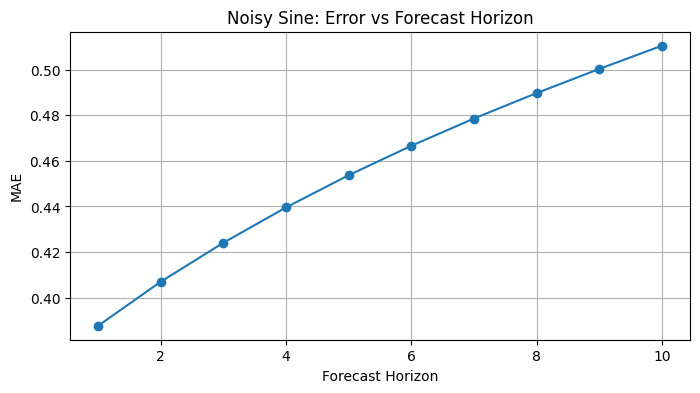

In [20]:
sine_horizon_errors = forecast_horizon(
    sine_model,
    sine_splits["test"][0],
    sine_splits["test"][1],
    sine_y_scaler
)

plt.figure(figsize=(8, 4))

plt.plot(
    range(1, 11),
    sine_horizon_errors,
    marker="o"
)

plt.xlabel("Forecast Horizon")
plt.ylabel("MAE")
plt.title("Noisy Sine: Error vs Forecast Horizon")
plt.grid()
plt.show()

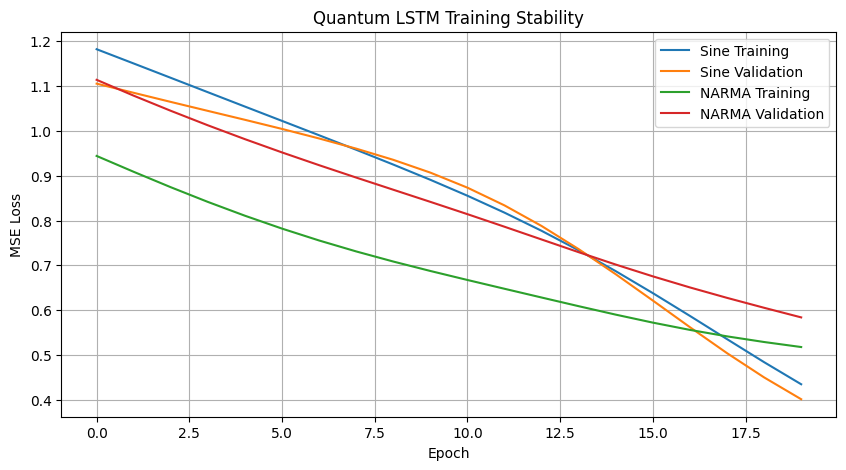

In [21]:
plt.figure(figsize=(10, 5))

plt.plot(
    sine_train_losses,
    label="Sine Training"
)

plt.plot(
    sine_val_losses,
    label="Sine Validation"
)

plt.plot(
    narma_train_losses,
    label="NARMA Training"
)

plt.plot(
    narma_val_losses,
    label="NARMA Validation"
)

plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("Quantum LSTM Training Stability")

plt.legend()
plt.grid()
plt.show()

In [22]:
circuit_info = qml.specs(quantum_circuit)(
    torch.tensor([0.1, 0.2, 0.3, 0.4]),
    torch.zeros((n_layers, n_qubits, 3))
)

circuit_depth = circuit_info["resources"].depth

print("QUANTUM COMPUTATIONAL COST")
print("--------------------------")

print("Qubits:", n_qubits)
print("Circuit Depth:", circuit_depth)
print("Shots: None (analytic simulation)")

print("\nNOISY SINE")
print("Training Time:", sine_time)
print("Inference Time:", sine_results[3])
print("\nNARMA-10")
print("Training Time:", narma_time)
print("Inference Time:", narma_results[3])

QUANTUM COMPUTATIONAL COST
--------------------------
Qubits: 4
Circuit Depth: 2
Shots: None (analytic simulation)

NOISY SINE
Training Time: 5.310824871063232
Inference Time: 0.0629568099975586

NARMA-10
Training Time: 4.071471214294434
Inference Time: 0.06098818778991699


In [23]:
comparison = pd.DataFrame({

    "Metric": [
        "MAE",
        "RMSE",
        "R2",
        "Residual Bias",
        "Qubits",
        "Circuit Depth",
        "Shots",
        "Training Time",
        "Inference Time"
    ],

    "Noisy Sine": [
        mean_absolute_error(sine_results[0], sine_results[1]),
        np.sqrt(mean_squared_error(sine_results[0], sine_results[1])),
        r2_score(sine_results[0], sine_results[1]),
        np.mean(sine_results[2]),
        n_qubits,
        circuit_depth,
        "Analytic",
        sine_time,
        sine_results[3]
    ],

    "NARMA-10": [
        mean_absolute_error(narma_results[0], narma_results[1]),
        np.sqrt(mean_squared_error(narma_results[0], narma_results[1])),
        r2_score(narma_results[0], narma_results[1]),
        np.mean(narma_results[2]),
        n_qubits,
        circuit_depth,
        "Analytic",
        narma_time,
        narma_results[3]
    ]
})

print(comparison.to_string(index=False))

        Metric Noisy Sine  NARMA-10
           MAE   0.387615  0.060589
          RMSE   0.449051  0.074149
            R2    0.62998   0.31057
 Residual Bias   0.060065 -0.018199
        Qubits          4         4
 Circuit Depth          2         2
         Shots   Analytic  Analytic
 Training Time   5.310825  4.071471
Inference Time   0.062957  0.060988
